# Variable selection with L1-penalised logistic regression
*Taiwanese bankruptcy prediction, Augmented Decision final project*

This notebook prepares the **variable-selection** half of the project's combined approach: variable selection followed by a decision-tree classifier (*Project requirements*, p. 1). It builds reproducible candidate input sets for a future decision tree, and stops before any tree is trained.

## 1. Purpose, and what remains undecided
The data describe each record with 95 financial indicators. Some are redundant, near-copies of each other, and some may carry little useful information about bankruptcy. A shorter list of inputs is easier to explain and to check. In this notebook we:

1. use **L1-penalised logistic regression** to create several candidate sets of input variables, one per regularisation setting $C$;
2. examine how those sets change **with the amount of regularisation** and **with the training sample**;
3. set aside a **test set** and save reproducible **development folds** for the next stage.

This notebook does **not** choose the final $C$, train a decision tree or report any final predictive performance. Those decisions belong to the next stage, described in Section 13.

**What is being predicted.** The target is the column `Bankrupt?`, where **1 = bankrupt (the positive class)** and 0 = not bankrupt. Each row is a company-related financial record, not necessarily a unique company: the file has no company identifier and no observation date. It therefore establishes no forecasting horizon, and no timing of the indicators relative to the bankruptcy. We treat the exercise as a **retrospective analysis of recorded bankruptcy labels**. Source: [UCI Machine Learning Repository, Taiwanese Bankruptcy Prediction](https://archive.ics.uci.edu/dataset/572/taiwanese+bankruptcy+prediction).

### Key terms
- **Target**: the quantity we want to explain or predict, here `Bankrupt?`.
- **Predictor** (also *variable* or *input*): a column used to help predict the target, here each financial indicator.
- **Coefficient**: the weight a linear model gives to a predictor. A coefficient of exactly zero means the model ignores that predictor.
- **Scaling**: re-expressing every predictor on a comparable scale (here mean 0 and standard deviation 1), so that coefficients can be compared and penalised fairly.
- **Regularisation**: adding a cost for large coefficients during fitting, which keeps the model simple. Its strength is set by $C$, and **a smaller $C$ means stronger regularisation**.
- **Validation fold**: a group of records held out of fitting, so that a procedure can later be checked on records it did not learn from.
- **Data leakage**: information from records that should be unseen (validation or test records) influencing a fitting step. Leakage makes results look better than they would be on new data ([scikit-learn: common pitfalls](https://scikit-learn.org/stable/common_pitfalls.html)).

### Scope and reproducibility
- Run the notebook from the **project root** (the folder containing `data/`); every path is relative to it.
- Every random choice uses the fixed seed 42, and all settings sit in the single configuration cell below.
- The notebook writes five files to `outputs/variable_selection/`. With them, the next stage can rebuild exactly the same split and folds and refit the same procedure from the raw data.
- The project requires full, verbatim disclosure of relevant LLM exchanges in the final report (*Project requirements*, p. 2). That disclosure belongs in the report's appendix; this notebook does not provide it.

### Configuration
The next cell imports the libraries and fixes every setting used below; nothing later changes them. Its output only confirms the software versions. The scikit-learn version matters because it decides how a pure L1 penalty is requested: the installed version expects `l1_ratio=1`, where older versions used `penalty="l1"`.

In [1]:
import hashlib
import io
import json
import platform
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler

# Data and outputs
DATA_PATH = Path("data/data.csv")
OUTPUT_DIR = Path("outputs/variable_selection")
OUTPUT_FILES = ["run_manifest.json", "split_assignments.csv", "selection_fits.csv",
                "feature_selection.csv", "candidate_summary.csv"]
TARGET = "Bankrupt?"                 # 1 = bankrupt (positive class), 0 = not bankrupt

# Development/test split and cross-validation
SEED = 42                            # used for the split and for the folds
TEST_SIZE = 0.20
N_FOLDS = 5                          # stratified and shuffled

# L1-penalised logistic selector
C_VALUES = [0.01, 0.1, 1.0, 10.0]    # smaller C = stronger regularisation
L1_RATIO = 1                         # pure L1 penalty (syntax of the installed scikit-learn)
SOLVER = "saga"
FIT_INTERCEPT = True                 # intercept included; saga does not penalise it
CLASS_WEIGHT = None
ESTIMATOR_RANDOM_STATE = 42
SOLVER_TOLERANCE = 1e-4
INITIAL_MAX_ITER = 20_000
RETRY_MAX_ITER = 100_000             # one retry allowed if the first fit does not converge
COEFFICIENT_THRESHOLD = 1e-6         # selected if |standardised coefficient| >= threshold

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
GREY, ORANGE = "#9aa5b1", "#c2571a"

print(f"Python {platform.python_version()} | NumPy {np.__version__} | pandas {pd.__version__} "
      f"| scikit-learn {sklearn.__version__}")

Python 3.13.5 | NumPy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1


## 2. Load and check the data
A data table holds three kinds of content:
- a **row** is one record, here one company-related financial record;
- a **predictor column** holds one financial indicator for every record;
- the **target column** `Bankrupt?` holds the outcome we want to explain.

The next cell reads the CSV and strips the stray spaces around column names (the raw names start with a space). It then gives each row a **`source_row_id`**, its zero-based position in the original file. This ID is bookkeeping only and is never used as a predictor. The cell also computes a **SHA-256 hash** of the raw file, a fingerprint that changes if a single byte changes, so the next stage can confirm it uses the same file. If the file cannot be found, the cell stops and explains why.

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"'{DATA_PATH}' was not found from the working directory {Path.cwd()}. Start Jupyter with the "
        "project root (the folder that contains 'data/' and 'context/') as the working directory.")

raw_bytes = DATA_PATH.read_bytes()
data_sha256 = hashlib.sha256(raw_bytes).hexdigest()

data = pd.read_csv(io.BytesIO(raw_bytes))
data.columns = data.columns.str.strip()                       # raw names start with a space
assert data.columns.is_unique, "Column names are no longer unique after stripping spaces."
data.index = pd.RangeIndex(len(data), name="source_row_id")   # zero-based position in the CSV

predictor_names = [name for name in data.columns if name != TARGET]
predictors, target = data[predictor_names], data[TARGET]

print(f"SHA-256 of {DATA_PATH}: {data_sha256}")
print(f"{len(data):,} rows | {len(predictor_names)} predictor columns | target column '{TARGET}'")

SHA-256 of data/data.csv: 67bf2e7c75490f7ad3f76bbce57d49cdc25967cdab607527b94f944863fa14d8
6,819 rows | 95 predictor columns | target column 'Bankrupt?'


Next, a small **audit table** checks that the data can be used as they are: the target's values and class counts, whether every predictor is numeric, missing or infinite values, and duplicate records. If any problem appears, the cell stops with an explanation rather than silently repairing the data: we do not impute, drop or correct anything.

In [3]:
all_numeric = all(pd.api.types.is_numeric_dtype(predictors[name]) for name in predictor_names)
n_missing = int(data.isna().sum().sum())
n_infinite = int(np.isinf(predictors.to_numpy(dtype=float)).sum()) if all_numeric else None
n_duplicate_rows = int(data.duplicated().sum())
n_duplicate_predictor_rows = int(predictors.duplicated().sum())
class_counts = target.value_counts().sort_index()

problems = []
if set(class_counts.index) != {0, 1}:
    problems.append(f"target values are {sorted(class_counts.index)}, expected 0 and 1")
if not all_numeric:
    problems.append("some predictors are not numeric")
if n_missing or n_infinite:
    problems.append(f"{n_missing} missing and {n_infinite} infinite values")
if n_duplicate_rows or n_duplicate_predictor_rows:
    problems.append(f"{n_duplicate_rows} duplicate rows, {n_duplicate_predictor_rows} duplicate predictor rows")
if problems:
    raise ValueError("Resolve these data issues explicitly before continuing: " + "; ".join(problems))

pd.Series({
    "rows": len(data),
    "columns (after stripping names)": data.shape[1],
    "candidate predictor columns": len(predictor_names),
    "target values": ", ".join(str(value) for value in class_counts.index),
    "records with target 0 (not bankrupt)": class_counts[0],
    "records with target 1 (bankrupt)": class_counts[1],
    "all predictors numeric": all_numeric,
    "missing values": n_missing,
    "infinite values": n_infinite,
    "duplicate full rows": n_duplicate_rows,
    "duplicate predictor rows (target ignored)": n_duplicate_predictor_rows,
}, name="value").to_frame()

,value
rows,6819
columns (after stripping names),96
candidate predictor columns,95
target values,"0, 1"
records with target 0 (not bankrupt),6599
records with target 1 (bankrupt),220
all predictors numeric,True
missing values,0
infinite values,0
duplicate full rows,0


**Result from this run.** The file has 6,819 records and 95 numeric predictors: 220 records are bankrupt and 6,599 are not. There are no missing or infinite values, no duplicate rows and no duplicate predictor rows, so nothing needs repairing.

The next plot shows how rare the positive class is: each bar gives a class's record count and its share of the file.

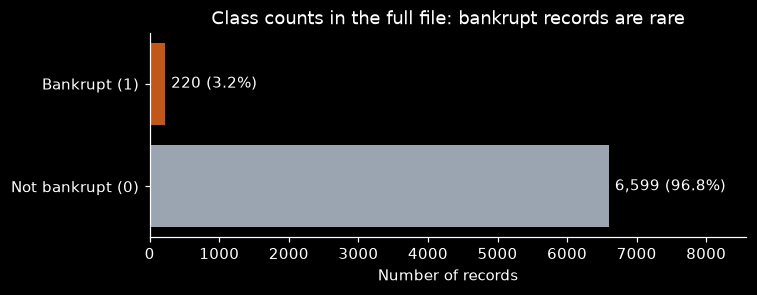

In [4]:
fig, ax = plt.subplots(figsize=(7, 2.4))
bars = ax.barh(["Not bankrupt (0)", "Bankrupt (1)"], class_counts.values, color=[GREY, ORANGE])
ax.bar_label(bars, labels=[f"{n:,} ({n / len(target):.1%})" for n in class_counts.values], padding=4)
ax.set(xlim=(0, class_counts.max() * 1.3), xlabel="Number of records",
       title="Class counts in the full file: bankrupt records are rare")
plt.show()

**Result from this run.** Only 3.2% of records are bankrupt (220 of 6,819). With so few positive records, a selection fitted on one sample of the data can change noticeably on another, and later validation scores will be noisy. Checking how stable the selections are, and keeping a test set apart, are therefore especially important.

## 3. Establish the development/test boundary
- **Development data** (80%) are available for learning the procedure and, in the next stage, for choosing its settings.
- **Test data** (20%) are reserved for one final assessment, after every choice has been frozen (*Empirical risk and generalization*, pp. 2–3).
- **Stratification** keeps approximately the same share of bankrupt records in both sets.

The next cell splits the source row IDs with the fixed seed. It then sorts each set in ascending `source_row_id` order: sorting does not change which record is in which set, but it makes the split easy to rebuild. Finally it checks that every record lands in exactly one set. The output table gives the number of records and bankruptcies in each set.

In [5]:
source_row_ids = data.index.to_numpy()
development_ids, test_ids = train_test_split(
    source_row_ids, test_size=TEST_SIZE, stratify=target, random_state=SEED)
development_ids, test_ids = np.sort(development_ids), np.sort(test_ids)   # same members, stable order

development_predictors = predictors.loc[development_ids]
development_target = target.loc[development_ids]
test_predictors = predictors.loc[test_ids]        # set aside: not used again in this notebook
test_target = target.loc[test_ids]                # used only for the counts below

assert set(development_ids).isdisjoint(test_ids), "A record is in both sets."
assert np.array_equal(np.sort(np.concatenate([development_ids, test_ids])), source_row_ids), "Records are missing."

pd.DataFrame({"records": [len(development_ids), len(test_ids)],
              "bankrupt": [int(development_target.sum()), int(test_target.sum())],
              "bankrupt share": [development_target.mean(), test_target.mean()]},
             index=["development", "test"]).round(4)

,records,bankrupt,bankrupt share
development,5455,176,0.0323
test,1364,44,0.0323


**Result from this run.** The development set holds 5,455 records (176 bankrupt) and the test set 1,364 records (44 bankrupt); both keep a 3.2% share of bankruptcies.

From here on, **the test data are set aside**. No test predictor is used for statistics, scaling, cleanup or selection, and the test labels served only for the counts above. Holding them out is what will let the final assessment be an honest check (*Empirical risk and generalization*, p. 15).

A random stratified split does not make records independent: the same company may appear in several records, and records from different years are mixed together. Without identifiers or dates we cannot check either issue, so any later performance estimate assumes that records behave like independent draws.

## 4. Create and save the five development folds
**Cross-validation**, in plain words: divide the development data into five groups (**folds**) of similar size and class mix. Fit on four groups and hold out the fifth, then repeat five times so that each record is held out exactly once.

The next cell creates these folds once (stratified, shuffled, seed 42) on the development rows in ascending `source_row_id` order, and records each development row's validation fold by its `source_row_id`. It checks that the five validation folds are disjoint and together cover the development data exactly once. The table gives the size and the number of bankruptcies of each fold's training part and validation part.

In [6]:
fold_splitter = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
fold_pairs = list(fold_splitter.split(development_predictors, development_target))  # positions in development data

validation_fold = pd.Series(pd.NA, index=data.index, dtype="Int64", name="cv_validation_fold")
for fold_number, (_, validation_positions) in enumerate(fold_pairs, start=1):
    validation_fold.loc[development_ids[validation_positions]] = fold_number

all_validation_positions = np.concatenate([validation for _, validation in fold_pairs])
assert len(np.unique(all_validation_positions)) == len(all_validation_positions) == len(development_ids), \
    "Validation folds overlap or miss development records."
assert validation_fold.loc[development_ids].notna().all() and validation_fold.loc[test_ids].isna().all()

pd.DataFrame([{"training records": len(training), "training bankrupt": int(development_target.iloc[training].sum()),
               "validation records": len(validation),
               "validation bankrupt": int(development_target.iloc[validation].sum())}
              for training, validation in fold_pairs],
             index=pd.Index(range(1, N_FOLDS + 1), name="fold"))

,training records,training bankrupt,validation records,validation bankrupt
fold,,,,
1,4364,140,1091,36
2,4364,141,1091,35
3,4364,141,1091,35
4,4364,141,1091,35
5,4364,141,1091,35


**Result from this run.** Each training part holds 4,364 records with 140 or 141 bankruptcies, and each validation fold holds 1,091 records with 35 or 36 bankruptcies.

In this notebook the folds serve two purposes:
1. **Description.** We fit the selector on each fold's **training part only**, to see how its choices vary from one training sample to another. The validation parts are not used to score or tune the selector.
2. **A reusable structure.** The next stage will evaluate the complete selection-plus-tree procedure on exactly these folds. Fitting every step inside the training part is what the project requires (*Project requirements*, p. 2; *Regularization and variable selection*, p. 17).

The next cell saves each record's assignment (development fold 1–5, or test) to `split_assignments.csv`, in ascending `source_row_id` order. The file stores no predictor or target values. The output counts the records in each group.

In [7]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
split_assignments = pd.DataFrame({
    "source_row_id": source_row_ids,
    "split": np.where(np.isin(source_row_ids, development_ids), "development", "test"),
    "cv_validation_fold": validation_fold.array,          # blank for test rows
})
split_assignments.to_csv(OUTPUT_DIR / "split_assignments.csv", index=False)
split_assignments.groupby(["split", "cv_validation_fold"], dropna=False).size().rename("records").to_frame()

records
split       cv_validation_fold         
development 1                      1091
            2                      1091
            3                      1091
            4                      1091
            5                      1091
test        <NA>                   1364

Every development record has exactly one validation fold, and test records have none.

## 5. Structural cleanup and scaling
**Structural cleanup.** Two kinds of columns cannot help any model, whatever the target:
- a **constant** column, with the same value in every training record, cannot tell bankrupt and non-bankrupt records apart;
- two **identical** columns contain the same recorded information twice.

Removing them is **structural cleanup**: it looks only at predictor values, never at the target, so it is **not evidence** about whether a predictor is related to bankruptcy. Like every fitted step, it is learned on training records only. The resulting list of kept columns is then applied unchanged to any other records, never relearned on them.

The next cell defines `structural_cleanup`. Given a training table, it marks constant columns, then compares the remaining columns for **exact** equality: not rounded, and not merely "highly correlated". Values in this dataset have very different scales, and high correlation is not duplication. In each identical group, the first column in CSV order is kept and later ones are marked as duplicates of it. The function returns the kept names and a reason for every predictor.

In [8]:
def structural_cleanup(training_predictors):
    """Find constant and exactly identical columns, using the supplied training rows only."""
    names = list(training_predictors.columns)
    values = training_predictors.to_numpy()
    status = {name: "retained" for name in names}
    duplicate_of = {name: None for name in names}
    retained = {}                                         # retained name -> its column of values

    for j, name in enumerate(names):
        column = values[:, j]
        if (column == column[0]).all():
            status[name] = "constant"
            continue
        duplicate_found = False
        for kept_name, kept_column in retained.items():   # earlier retained columns, in CSV order
            if np.array_equal(column, kept_column):
                status[name], duplicate_of[name] = "duplicate", kept_name
                duplicate_found = True
                break
        if not duplicate_found:
            retained[name] = column

    reasons = pd.DataFrame({"feature": names,
                            "cleanup_status": [status[name] for name in names],
                            "duplicate_of": [duplicate_of[name] for name in names]})
    return list(retained), reasons

As a check, we apply the cleanup to the full development data (test rows excluded). The table lists only the predictors that it excludes. Each fold will repeat this on its own training part, so fold-specific constant columns may differ.

In [9]:
development_retained, development_cleanup = structural_cleanup(development_predictors)
print(f"{len(development_retained)} of {len(predictor_names)} predictors retained on the development data")
development_cleanup[development_cleanup["cleanup_status"] != "retained"]

92 of 95 predictors retained on the development data


,feature,cleanup_status,duplicate_of
76,Current Liability to Liability,duplicate,Current Liabilities/Liability
77,Current Liability to Equity,duplicate,Current Liabilities/Equity
93,Net Income Flag,constant,NaN


**Result from this run.** On the development data, 92 of the 95 predictors are retained. `Net Income Flag` is constant, and two columns are exact copies of earlier ones under different names: `Current Liability to Liability` duplicates `Current Liabilities/Liability`, and `Current Liability to Equity` duplicates `Current Liabilities/Equity`. This matches the earlier inspection of the file.

**Scaling.** The L1 penalty charges each coefficient by its absolute size, and a coefficient's size depends on the units of its predictor. Without a common scale, the penalty would treat predictors unequally, so we first scale them on the training records only (*Gaussian regression and variable selection*, p. 21). We use **standardisation**:

$$
z_{ij} = \frac{x_{ij} - \mu_j}{s_j},
$$

where $x_{ij}$ is the recorded value of predictor $j$ for record $i$, $\mu_j$ is the mean of predictor $j$ over the training records, $s_j$ is its standard deviation over the same records, and $z_{ij}$ is the standardised value. After this step, every predictor has mean 0 and standard deviation 1 in the training data. We use scikit-learn's `StandardScaler`, which learns $\mu_j$ and $s_j$ from the records it is fitted on.

Standardisation only shifts and rescales. It does **not** change what a predictor measures, repair faulty encoding, make values normally distributed or remove the influence of extreme values. The next cell shows this on five development predictors, two ordinary ones and three with extreme values. For each it gives the raw minimum, median and maximum, then the median and the largest absolute standardised value.

In [10]:
example_names = ["ROA(A) before interest and % after tax", "Debt ratio %", "Cash Turnover Rate",
                 "Total Asset Growth Rate", "Quick Ratio"]
example_raw = development_predictors[example_names]
example_z = pd.DataFrame(StandardScaler().fit_transform(example_raw), columns=example_names)

pd.DataFrame({"raw minimum": example_raw.min(), "raw median": example_raw.median(),
              "raw maximum": example_raw.max(), "median z": example_z.median(),
              "largest |z|": example_z.abs().max()}).map(lambda value: f"{value:.3g}")

,raw minimum,raw median,raw maximum,median z,largest |z|
ROA(A) before interest and % after tax,0,0.559,1,0.0237,8.54
Debt ratio %,0,0.111,1,-0.034,16.3
Cash Turnover Rate,0,1.14e+09,1e+10,-0.46,2.54
Total Asset Growth Rate,0,6.4e+09,9.98e+09,0.308,1.91
Quick Ratio,0,0.00736,9.23e+09,-0.034,38.3


**Result from this run.** The first two predictors behave ordinarily: they lie between 0 and 1, and their largest standardised values stay moderate (8.5 and 16.3). The other three show that the supplied values are **not** all on a $[0, 1]$ scale, since they reach about $10^{10}$:
- In `Cash Turnover Rate` and `Total Asset Growth Rate`, most records sit at very large values, so standardisation squeezes all the small values together.
- In `Quick Ratio`, a handful of records near $10^9$ dominate the mean and the standard deviation. The median record ends up at $z \approx -0.03$, while the extreme records reach $|z| \approx 38$.

Standardisation leaves these extreme records just as influential as before. We keep the recorded values as they are, with no clipping and no guessed corrections, and note this as a limitation of the linear selector.

The tree of the next stage will receive the kept columns in their **original supplied scale**: standardisation belongs to the selector only. The supplied values may already have been transformed by the data provider, so tree thresholds should not be read as real financial units without documentation.

## 6. How L1-penalised logistic selection works
**From predictors to a probability.** A **coefficient** $\beta_j$ is the weight the linear model gives to standardised predictor $j$. The model adds up the weighted predictors and an intercept to get a score, then squeezes that score into a number between 0 and 1, read as an estimated probability of bankruptcy:

$$
q_i = \frac{1}{1 + \exp\!\big[-(b_0 + z_i^\top \beta)\big]},
$$

where $z_i$ is the list (vector) of standardised predictor values of record $i$, $\beta$ is the vector of coefficients, $z_i^\top\beta = \sum_j z_{ij}\beta_j$ is their weighted sum, $b_0$ is the **intercept** (the baseline level of the score when every standardised predictor equals 0), and $q_i$ is the estimated probability that record $i$ is bankrupt.

**Hypothetical illustration.** The next cell evaluates this formula for five made-up scores $b_0 + z_i^\top\beta$. For each resulting probability $q$, it also shows the **logistic loss** (defined just after the table) under both possible outcomes.

In [11]:
example_scores = np.array([-4.0, -2.0, 0.0, 2.0, 4.0])      # hypothetical values of b0 + z'beta
probability = 1 / (1 + np.exp(-example_scores))
pd.DataFrame({"score b0 + z'β": example_scores,
              "probability q": probability,
              "loss if bankrupt (y = 1)": -np.log(probability),
              "loss if not bankrupt (y = 0)": -np.log(1 - probability)}).round(3)

,score b0 + z'β,probability q,loss if bankrupt (y = 1),loss if not bankrupt (y = 0)
0,-4.0,0.018,4.018,0.018
1,-2.0,0.119,2.127,0.127
2,0.0,0.500,0.693,0.693
3,2.0,0.881,0.127,2.127
4,4.0,0.982,0.018,4.018


**Reading the table.** A score of 0 gives probability 0.5; large positive scores approach 1 and large negative scores approach 0. The **logistic loss** of a probability $q$ is $-\log q$ when the record is bankrupt ($y = 1$) and $-\log(1-q)$ when it is not ($y = 0$) (*Empirical risk and generalization*, p. 24, appendix). It is small when the probability agrees with the outcome and grows quickly when the model is **confidently wrong**. In the table, a probability of 0.018 for a record that turns out bankrupt costs 4.018, against 0.018 for the confident, correct probability of 0.982.

**Adding a cost for coefficients.** Fitting chooses $b_0$ and $\beta$ to make the average loss small. **Regularisation** adds a price for the size of the coefficients, so the model gives weight to a predictor only if doing so reduces the loss by enough to pay for it (*Regularization and variable selection*, p. 2). The **L1 penalty** charges the absolute values of the coefficients, and it has a useful property: it can set coefficients **exactly to zero** (*Regularization and variable selection*, p. 7). The fitted model solves

$$
\min_{b_0,\,\beta}\; \frac{1}{n}\sum_{i=1}^{n}\Big[-y_i \log q_i - (1-y_i)\log(1-q_i)\Big] \;+\; \lambda \sum_{j} |\beta_j| ,
$$

where $n$ is the number of training records, $y_i \in \{0, 1\}$ is the recorded outcome of record $i$, $q_i$ is its estimated probability (formula above, which depends on $b_0$ and $\beta$), $\beta_j$ is the coefficient of predictor $j$, and $\lambda \ge 0$ is the **penalty strength**. The intercept $b_0$ only sets the baseline level and is not included in the penalty.

**$\lambda$ and $C$.** scikit-learn sets the penalty through $C$, the **inverse** of the regularisation strength: **a smaller $C$ means stronger penalisation, and usually fewer predictors**. $C$ is not the same number as $\lambda$, because their numerical relationship depends on how the objective is normalised, for example whether the loss is summed or averaged over records (*Regularization and variable selection*, p. 18). We therefore work with $C$ only, and compare its values with each other.

**From coefficients to a selection.** The predictors kept for the tree are those with a non-zero coefficient. A numerical solver never returns perfectly exact numbers, so we use a fixed tolerance: a predictor is **selected** if $|\beta_j| \ge 10^{-6}$. *Hypothetical example:* coefficients $(0.6,\ 0,\ -0.2)$ select the first and third predictors.

What to expect, and what not to claim:
- Stronger regularisation (smaller $C$) generally encourages a smaller subset, that is, a **sparse** model (*Gaussian regression and variable selection*, p. 13). With correlated predictors and numerical fits, the number and names of selected predictors **need not change monotonically** at every step. We do not force them to.
- The course develops the lasso with squared error, for a continuous response in a Gaussian regression setting. We keep its **L1 selection principle** and **adapt** it to a binary outcome by using the logistic loss. The course's soft-thresholding formula (*Regularization and variable selection*, pp. 8–9) holds for orthogonal predictors only and is not the algorithm used here; scikit-learn's `saga` solver fits the model numerically. Likewise, the course's minimax rates and exact-support guarantees rest on assumptions we cannot verify here, so they do not automatically apply to this dataset or to the future selection-plus-tree procedure (*Regularization and variable selection*, pp. 16 and 24).
- L1 selection is **supervised**: it uses the target labels of its training data. It is a tool to choose inputs, not the final classifier, so we report **no** accuracy or other classification score for it.
- A selected list is a diagnostic, **not a proven best subset**, and a selected variable **need not be used** by the future tree.
- A **zero coefficient** does not prove that a variable is useless or unrelated to bankruptcy: with correlated predictors, the model can rely on a near-copy instead (*Gaussian regression and variable selection*, p. 18). A **non-zero coefficient** does not establish causation or statistical significance.
- A linear selector can miss information that matters only through non-linear relationships or interactions, which a tree can capture (*Decision trees using weak learners*, p. 8). The future tree **without** supervised selection is therefore an essential comparator.

Forward selection (*Gaussian regression and variable selection*, p. 20) is the course's other way of choosing variables; the agreed experiment uses L1 selection only. Further reading: [scikit-learn, L1-based feature selection](https://scikit-learn.org/stable/modules/feature_selection.html#l1-based-feature-selection).

## 7. The fitting routine
The next cell defines `fit_l1_selector`, the single function that performs one selection fit. Its inputs make the information boundary explicit: a **training predictor table**, the matching **training target** and one value of $C$. It never sees validation or test records. It:
1. runs `structural_cleanup` on the training records;
2. fits `StandardScaler` on the kept training columns;
3. fits the L1 logistic regression with the fixed settings ([scikit-learn documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html));
4. returns a dictionary with the cleanup reasons, the kept names, the fitted scaler and model, the standardised coefficients, the selected names and the convergence record.

**Convergence.** The solver improves the coefficients step by step, and stops when the changes become tiny (tolerance $10^{-4}$) or when it reaches its iteration limit. If it hits the limit first, scikit-learn emits a `ConvergenceWarning`. The function catches that warning and retries **once**, from a fresh model, with 100,000 iterations instead of 20,000. If the retry also fails, the fit is recorded as **invalid**: it reports no coefficients and no selection, so it cannot be mistaken for evidence. A converged fit that selects nothing is recorded as such, and no predictor is added back. Any other warning is shown, and any other error stops the notebook.

In [12]:
def fit_l1_selector(training_predictors, training_target, C):
    """Cleanup, scaling and L1 logistic fit, learned from the supplied training rows only."""
    retained_names, cleanup_table = structural_cleanup(training_predictors)
    scaler = StandardScaler().fit(training_predictors[retained_names])
    standardized = scaler.transform(training_predictors[retained_names])

    for max_iter in (INITIAL_MAX_ITER, RETRY_MAX_ITER):          # at most one retry
        model = LogisticRegression(l1_ratio=L1_RATIO, C=C, solver=SOLVER, fit_intercept=FIT_INTERCEPT,
                                   class_weight=CLASS_WEIGHT, tol=SOLVER_TOLERANCE, max_iter=max_iter,
                                   random_state=ESTIMATOR_RANDOM_STATE)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            model.fit(standardized, training_target)
        converged = not any(issubclass(w.category, ConvergenceWarning) for w in caught)
        for w in caught:                                          # never hide other warnings
            if not issubclass(w.category, ConvergenceWarning):
                warnings.warn(w.message, w.category)
        if converged:
            break

    coefficients = pd.Series(model.coef_.ravel(), index=retained_names) if converged else None
    selected_names = list(coefficients.index[coefficients.abs() >= COEFFICIENT_THRESHOLD]) if converged else None
    return {
        "C": C, "cleanup_table": cleanup_table, "retained_names": retained_names,
        "scaler": scaler, "model": model, "coefficients": coefficients, "selected_names": selected_names,
        "n_training_rows": len(training_target), "n_training_positive": int(training_target.sum()),
        "n_predictors_after_cleanup": len(retained_names),
        "n_selected": len(selected_names) if converged else pd.NA,
        "converged": converged, "n_iter": int(model.n_iter_.max()), "max_iter_used": max_iter,
        "usable_nonempty_selection": bool(converged and len(selected_names) > 0),
    }

## 8. Fit the four candidates within the training folds
The next cell runs a nested loop over the 5 saved folds and the 4 values of $C$. Each time, it calls `fit_l1_selector` on **that fold's training records only**: 20 fits, plus any retries. Cleanup, scaling and coefficients are refitted from scratch every time, and nothing fitted on one fold is reused on another. The validation records are not touched, and no winner is picked. The loop takes a few minutes and prints, for each fold, the number of predictors selected under each $C$.

In [13]:
cv_fits = []
for fold_number, (training_positions, _) in enumerate(fold_pairs, start=1):   # validation part unused
    training_predictors = development_predictors.iloc[training_positions]
    training_target = development_target.iloc[training_positions]
    for C in C_VALUES:
        result = fit_l1_selector(training_predictors, training_target, C)
        result.update(fit_scope="cv_training", fold=fold_number)
        cv_fits.append(result)
    print(f"fold {fold_number}: selected predictors for C = {C_VALUES}: "
          f"{[result['n_selected'] for result in cv_fits[-len(C_VALUES):]]}")

fold 1: selected predictors for C = [0.01, 0.1, 1.0, 10.0]: [5, 33, 73, 91]
fold 2: selected predictors for C = [0.01, 0.1, 1.0, 10.0]: [5, 28, 71, 88]
fold 3: selected predictors for C = [0.01, 0.1, 1.0, 10.0]: [6, 37, 74, 88]
fold 4: selected predictors for C = [0.01, 0.1, 1.0, 10.0]: [6, 33, 71, 91]
fold 5: selected predictors for C = [0.01, 0.1, 1.0, 10.0]: [5, 30, 74, 88]


The next cell gathers the 20 fit records into one table, with one row per fold and $C$. It prints how many fits converged and how many needed the retry, then shows the number of selected predictors as a compact fold × $C$ grid, where a blank cell would mean a fit that did not converge.

In [14]:
FIT_COLUMNS = ["fit_scope", "fold", "C", "n_training_rows", "n_training_positive", "n_predictors_after_cleanup",
               "n_selected", "converged", "n_iter", "max_iter_used", "usable_nonempty_selection"]
cv_fit_table = pd.DataFrame(cv_fits)[FIT_COLUMNS].astype({"fold": "Int64", "n_selected": "Int64"})

print(f"Converged fits: {cv_fit_table['converged'].sum()} of {len(cv_fit_table)} | fits that needed the retry: "
      f"{(cv_fit_table['max_iter_used'] == RETRY_MAX_ITER).sum()} | most solver iterations: {cv_fit_table['n_iter'].max():,}")
print("Predictors left after cleanup, folds 1-5:",
      cv_fit_table.groupby("fold")["n_predictors_after_cleanup"].first().tolist())
cv_fit_table.pivot(index="fold", columns="C", values="n_selected")

Converged fits: 20 of 20 | fits that needed the retry: 0 | most solver iterations: 5,865
Predictors left after cleanup, folds 1-5: [92, 92, 92, 92, 92]


C,0.01,0.10,1.00,10.00
fold,,,,
1,5,33,73,91
2,5,28,71,88
3,6,37,74,88
4,6,33,71,91
5,5,30,74,88


**Result from this run.** All 20 fits converged at the first attempt, using at most 5,865 solver iterations against a limit of 20,000. No retry was needed and no fit is invalid. Structural cleanup kept the same 92 predictors in every fold. The number of selected predictors grows steadily with $C$: about 5 at $C = 0.01$, about 30 at $C = 0.1$, about 70 at $C = 1$ and about 90 at $C = 10$.

Each value of $C$ has now been examined on five slightly different training samples. A selector fitted once on all development labels could **not** replace these fold-specific fits in a later cross-validation: it would have seen the labels of every validation fold, which is data leakage.

## 9. Subset size and stability
The next cell summarises the five folds for each $C$, in ascending order:
- how many fits converged;
- how many selected nothing;
- the mean, minimum and maximum number of selected predictors.

These statistics are reported only when all five fits converged. Otherwise they are left blank, because averaging only the successful folds would make an invalid candidate look comparable. The last column states whether a candidate has five converged, non-empty selections, which makes it **numerically eligible** for the next stage's tree search. That is not a performance recommendation, and no row is a "best" one.

In [15]:
candidate_rows = []
for C in C_VALUES:
    fits_for_C = cv_fit_table[cv_fit_table["C"] == C]
    all_converged = bool(fits_for_C["converged"].all())
    counts = fits_for_C["n_selected"]
    candidate_rows.append({
        "C": C,
        "n_converged_folds": int(fits_for_C["converged"].sum()),
        "n_zero_feature_folds": int((counts == 0).sum()),
        "cv_mean_selected": float(counts.mean()) if all_converged else np.nan,
        "cv_min_selected": counts.min() if all_converged else pd.NA,
        "cv_max_selected": counts.max() if all_converged else pd.NA,
        "cv_numerically_eligible": all_converged and bool((counts > 0).all()),
    })
candidate_summary = pd.DataFrame(candidate_rows).astype({"cv_min_selected": "Int64", "cv_max_selected": "Int64"})
candidate_summary

,C,n_converged_folds,n_zero_feature_folds,cv_mean_selected,cv_min_selected,cv_max_selected,cv_numerically_eligible
0,0.01,5,0,5.4,5,6,True
1,0.10,5,0,32.2,28,37,True
2,1.00,5,0,72.6,71,74,True
3,10.00,5,0,89.2,88,91,True


**Result from this run.** All four candidates have five converged, non-empty fold selections, so all four are numerically eligible for the next stage. Their subset sizes differ widely: $C = 0.01$ keeps 5–6 of the 92 available predictors, $C = 0.1$ keeps 28–37, $C = 1$ keeps 71–74 and $C = 10$ keeps 88–91. At $C = 10$ the selector removes only 1 to 4 predictors, so this candidate comes close to no selection at all.

The next plot shows the same information against $C$ on a **logarithmic** axis, where each step is a factor of 10. **Moving right, $C$ grows and regularisation weakens.** Each dot is the mean number of selected predictors over the five training folds, and its bar spans the fold minimum and maximum. This is a regularisation path in the spirit of *Regularization and variable selection*, p. 19. The dashed line is the number of predictors left after structural cleanup. A candidate without five converged fits would not be plotted as a dot, but marked with a red cross.

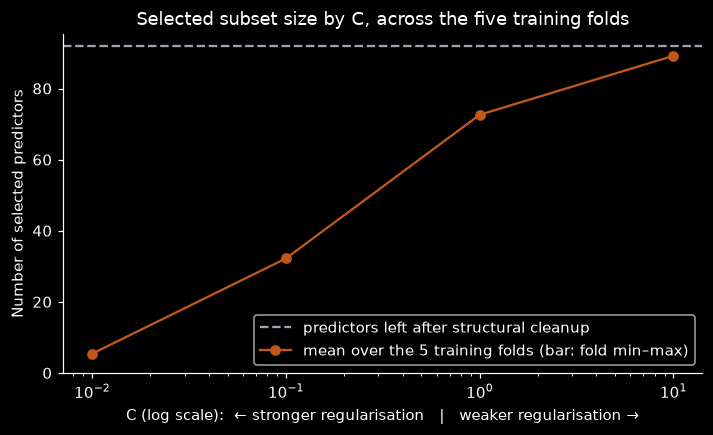

In [16]:
complete = candidate_summary[candidate_summary["n_converged_folds"] == N_FOLDS]
invalid_C = candidate_summary.loc[candidate_summary["n_converged_folds"] < N_FOLDS, "C"].tolist()
mean_selected = complete["cv_mean_selected"]
below = mean_selected - complete["cv_min_selected"].astype(float)
above = complete["cv_max_selected"].astype(float) - mean_selected

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.errorbar(complete["C"], mean_selected, yerr=[below, above], fmt="o-", color=ORANGE, ecolor="black",
            capsize=5, label="mean over the 5 training folds (bar: fold min–max)")
ax.axhline(cv_fit_table["n_predictors_after_cleanup"].max(), color=GREY, ls="--",
           label="predictors left after structural cleanup")
if invalid_C:
    ax.plot(invalid_C, [0] * len(invalid_C), "x", color="red", ms=10, label="not all 5 folds converged")
ax.set(xscale="log", ylim=(0, None), ylabel="Number of selected predictors",
       xlabel="C (log scale):  ← stronger regularisation   |   weaker regularisation →",
       title="Selected subset size by C, across the five training folds")
ax.legend(loc="lower right")
plt.show()

**Result from this run.** As expected, the subset size rises with $C$, from about 5 to about 89, close to the 92 predictors left after cleanup. The fold-to-fold range is narrowest at $C = 0.01$ (5–6) and widest at $C = 0.1$ (28–37). A similar *number* of predictors does not mean the same *names*, which is what the next tables examine.

**Which predictors are selected consistently?** For each $C$, the next cell counts in how many of the five training folds each predictor was selected; a structurally excluded predictor counts as not selected. The first table groups predictors into "selected in all 5 folds", "in 1–4 folds" and "in no fold". The second shows the 15 most frequently selected predictors, ordered by their total count over all fold fits and then by CSV order. This display rule only shortens the table: all counts can be rebuilt from the exported `feature_selection.csv`.

In [17]:
complete_C = complete["C"].tolist()
selection_counts = pd.DataFrame(0, index=predictor_names, columns=complete_C)
for result in cv_fits:
    if result["C"] in complete_C:
        selection_counts.loc[result["selected_names"], result["C"]] += 1

display(pd.DataFrame({f"C = {C:g}": {"selected in all 5 folds": int((selection_counts[C] == 5).sum()),
                                      "selected in 1–4 folds": int(selection_counts[C].between(1, 4).sum()),
                                      "selected in no fold": int((selection_counts[C] == 0).sum())}
                      for C in complete_C}))

total_label = f"total (of {N_FOLDS * len(complete_C)})"
(selection_counts.rename(columns=lambda C: f"C = {C:g}")
 .assign(**{total_label: selection_counts.sum(axis=1)}, csv_position=range(len(predictor_names)))
 .sort_values([total_label, "csv_position"], ascending=[False, True])
 .drop(columns="csv_position").head(15))

,C = 0.01,C = 0.1,C = 1,C = 10
selected in all 5 folds,4,13,43,85
selected in 1–4 folds,4,40,46,7
selected in no fold,87,42,6,3


,C = 0.01,C = 0.1,C = 1,C = 10,total (of 20)
Debt ratio %,5,5,5,5,20
Net worth/Assets,5,5,5,5,20
Net Income to Total Assets,5,4,5,5,19
Persistent EPS in the Last Four Seasons,2,5,5,5,17
Borrowing dependency,5,2,5,5,17
ROA(B) before interest and depreciation after tax,3,4,3,5,15
Net Value Per Share (B),0,5,5,5,15
Net Value Per Share (A),0,5,5,5,15
Quick Ratio,0,5,5,5,15
Accounts Receivable Turnover,0,5,5,5,15


**Result from this run.**
- **At $C = 0.01$**, 8 different predictors appear across the five folds, but only 4 are selected in every fold: `Debt ratio %`, `Net worth/Assets`, `Net Income to Total Assets` and `Borrowing dependency`. Others come and go, such as `ROA(B) before interest and depreciation after tax` (3 folds) and `Persistent EPS in the Last Four Seasons` (2 folds).
- **At $C = 0.1$**, the selection is the least consistent: 40 predictors are selected in some folds but not in others, against 13 selected in all five.
- **At $C = 10$**, 85 predictors are selected in every fold. The 3 never selected are the structurally excluded columns.
- **Selection does not always grow with $C$.** `Borrowing dependency` is selected in all 5 folds at $C = 0.01$ and at $C = 1$, but in only 2 at $C = 0.1$. As anticipated in Section 6, correlated predictors can swap places as the penalty changes.

These counts are **descriptive**. Any two training parts share 75% of their records (three of the five development folds), so they are not independent replications. The counts are not confidence intervals, not p-values and not probabilities that a predictor truly matters. The course's stability exercise refits on bootstrap resamples (*Regularization and variable selection*, p. 20); five overlapping folds are related, but not the same thing. We also do **not** build a consensus subset (a union, an intersection or a frequency cut-off), because that would be a new, untested selection method.

## 10. Four full-development candidate subsets
What does each $C$ select when **all** 5,455 development records are used? The next cell fits the same procedure once per $C$ on the full development data, with the test data still untouched and the same convergence and empty-selection rules. These four lists are **diagnostic candidate subsets**. They are not final choices, and they are not valid fixed inputs for a later cross-validation. The output gives each fit's convergence record and number of selected predictors.

In [18]:
full_development_fits = []
for C in C_VALUES:
    result = fit_l1_selector(development_predictors, development_target, C)
    result.update(fit_scope="full_development", fold=pd.NA)
    full_development_fits.append(result)

pd.DataFrame(full_development_fits)[["C", "converged", "n_iter", "max_iter_used",
                                     "n_predictors_after_cleanup", "n_selected"]]

,C,converged,n_iter,max_iter_used,n_predictors_after_cleanup,n_selected
0,0.01,True,935,20000,92,6
1,0.10,True,2801,20000,92,30
2,1.00,True,4660,20000,92,81
3,10.00,True,4858,20000,92,89


**Result from this run.** All four full-development fits converged at the first attempt. They select 6, 30, 81 and 89 of the 92 predictors left after cleanup. This is close to the fold fits, except at $C = 1$, where the full-development fit keeps 81 predictors against 71–74 in the folds (see Section 12).

The next table shows selected predictors with their **standardised coefficients**. To stay readable, it lists the predictors selected at the smallest $C$ (0.01), ordered by the size of their coefficient, with their coefficients under every $C$; a coefficient of 0 means "not selected at that $C$". The complete lists for all four values of $C$ are in `feature_selection.csv`, in the rows with `fit_scope = full_development`.

In [19]:
converged_full = [result for result in full_development_fits if result["converged"]]
coefficient_table = pd.DataFrame({f"C = {result['C']:g}": result["coefficients"] for result in converged_full})
smallest_C_selection = converged_full[0]["selected_names"]
(coefficient_table.loc[smallest_C_selection]
 .sort_values(coefficient_table.columns[0], key=abs, ascending=False).round(3))

,C = 0.01,C = 0.1,C = 1,C = 10
Net Income to Total Assets,-0.372,-0.339,-0.920,-1.051
Debt ratio %,0.222,0.517,0.553,0.642
Net worth/Assets,-0.222,-0.517,-0.553,-0.642
Persistent EPS in the Last Four Seasons,-0.095,-0.599,-0.888,-0.965
ROA(B) before interest and depreciation after tax,-0.093,-0.192,-0.141,-0.188
Borrowing dependency,0.012,0.000,0.576,0.692


**Reading the coefficients (result from this run).** A positive coefficient means that, within this fitted logistic selector and holding its other included predictors fixed, a higher value of the predictor goes with a higher estimated bankruptcy probability; a negative coefficient goes with a lower one. Here, the profitability indicators (`Net Income to Total Assets`, `Persistent EPS in the Last Four Seasons`, `ROA(B) before interest and depreciation after tax`) have negative coefficients, and `Borrowing dependency` has a positive one. These are associations inside one linear model. They are not causal effects or significance tests, and they do not describe what a future tree will do.

Two features of this table show the limits of reading coefficients:
- `Borrowing dependency` is selected at $C = 0.01$, dropped at $C = 0.1$ (coefficient 0) and selected again at $C = 1$ and $C = 10$. With correlated indicators, coefficients and even selected names can change between fits while predictions remain similar.
- `Debt ratio %` and `Net worth/Assets` receive exactly opposite coefficients under every $C$. To see why, the next cell adds the two columns record by record on the development data and reports the largest distance of their sum from 1.

In [20]:
pair_sum = development_predictors["Debt ratio %"] + development_predictors["Net worth/Assets"]
print(f"Largest |(Debt ratio % + Net worth/Assets) - 1| over development records: {(pair_sum - 1).abs().max():.1e}")

Largest |(Debt ratio % + Net worth/Assets) - 1| over development records: 1.1e-15


**Result from this run.** The two columns add up to 1 for every development record, up to a rounding error of about $10^{-15}$. One is the complement of the other, so after standardisation their values are exact opposites and they carry the same information. They are not identical columns, so structural cleanup rightly keeps both. The L1 fit cannot tell them apart, and splits the weight equally between them (*Gaussian regression and variable selection*, p. 18; *Regularization and variable selection*, p. 16). This is a concrete case where a selected list contains two predictors that offer a tree exactly the same splits.

> **These subsets use all development labels.** The next notebook must refit selection inside each training fold when comparing trees. It must **not** cross-validate a tree using one of these full-development lists as a fixed input list.

## 11. Export a reproducible handoff
We save plain CSV and JSON files: no pickled models and no transformed copies of the data. The next stage can then **refit** the transparent procedure from the raw data and the saved split. The next cell builds the three result tables:
- `selection_fits.csv`: one row per fit, covering the 20 fold fits and the 4 full-development fits;
- `feature_selection.csv`: one row per original predictor per fit, with its cleanup status, standardised coefficient and selected flag;
- `candidate_summary.csv`: one row per $C$, extending the table of Section 9 with the full-development results.

Empty fields are kept distinct from numeric zeros. An empty coefficient means "not available", either because cleanup removed the predictor or because the fit was invalid. A 0 means the L1 penalty set the coefficient to zero. The output shows the completed candidate summary.

In [21]:
all_fits = cv_fits + full_development_fits
selection_fits = pd.DataFrame(all_fits)[FIT_COLUMNS].astype({"fold": "Int64", "n_selected": "Int64"})

feature_tables = []
for result in all_fits:
    table = result["cleanup_table"].copy()
    table.insert(0, "fit_scope", result["fit_scope"])
    table.insert(1, "fold", result["fold"])
    table.insert(2, "C", result["C"])
    if result["converged"]:
        table["standardized_coefficient"] = table["feature"].map(result["coefficients"])  # empty if removed by cleanup
        table["selected"] = table["feature"].isin(result["selected_names"])
    else:                                    # invalid fit: nothing is known about any predictor
        table["standardized_coefficient"] = np.nan
        table["selected"] = pd.NA
    feature_tables.append(table)
feature_selection = pd.concat(feature_tables, ignore_index=True).astype({"fold": "Int64", "selected": "boolean"})

full_development_table = selection_fits[selection_fits["fit_scope"] == "full_development"].set_index("C")
candidate_summary["full_development_converged"] = candidate_summary["C"].map(full_development_table["converged"])
candidate_summary["full_development_n_selected"] = (
    candidate_summary["C"].map(full_development_table["n_selected"]).astype("Int64"))
candidate_summary

,C,n_converged_folds,n_zero_feature_folds,cv_mean_selected,cv_min_selected,cv_max_selected,cv_numerically_eligible,full_development_converged,full_development_n_selected
0,0.01,5,0,5.4,5,6,True,True,6
1,0.10,5,0,32.2,28,37,True,True,30
2,1.00,5,0,72.6,71,74,True,True,81
3,10.00,5,0,89.2,88,91,True,True,89


The next cell writes the three tables and `run_manifest.json`. The manifest records the data fingerprint, every setting, the software versions and the meaning of each file, and it states explicitly that **`final_C` is null**: choosing $C$ is deferred to the next stage. Rows are written in a fixed order, without the table index, so repeated runs produce identical files. The output lists the five files and their sizes.

In [22]:
manifest = {
    "schema_version": 1,
    "source_data": {"path": DATA_PATH.as_posix(), "sha256": data_sha256, "n_rows": int(len(data)),
                    "predictor_names": predictor_names},
    "target": {"name": TARGET, "labels": {"1": "bankrupt (positive class)", "0": "not bankrupt"}},
    "row_id_convention": "source_row_id = zero-based row position in the original CSV (header not counted)",
    "split": {"function": "sklearn.model_selection.train_test_split", "test_size": TEST_SIZE,
              "stratify": TARGET, "random_state": SEED,
              "row_order": "development and test IDs sorted in ascending source_row_id order after splitting"},
    "cross_validation": {"function": "sklearn.model_selection.StratifiedKFold", "n_splits": N_FOLDS,
                         "shuffle": True, "random_state": SEED,
                         "applied_to": "development rows in ascending source_row_id order",
                         "fold_labels": list(range(1, N_FOLDS + 1))},
    "selector": {
        "structural_cleanup": "per training subset: drop constant columns, then exact duplicates (keep first in CSV order)",
        "scaler": "sklearn.preprocessing.StandardScaler, fitted on each training subset",
        "model": "sklearn.linear_model.LogisticRegression",
        "l1_ratio": L1_RATIO, "solver": SOLVER, "fit_intercept": FIT_INTERCEPT, "intercept_penalized": False,
        "class_weight": CLASS_WEIGHT, "random_state": ESTIMATOR_RANDOM_STATE, "tol": SOLVER_TOLERANCE,
        "C_values": C_VALUES, "coefficient_threshold": COEFFICIENT_THRESHOLD,
        "selection_rule": "selected if abs(standardized coefficient) >= coefficient_threshold",
        "convergence_policy": {"initial_max_iter": INITIAL_MAX_ITER, "retry_max_iter": RETRY_MAX_ITER,
                               "max_retries": 1,
                               "if_still_not_converged": "fit recorded as invalid: no coefficients, no selection"},
    },
    "versions": {"python": platform.python_version(), "numpy": np.__version__,
                 "pandas": pd.__version__, "scikit-learn": sklearn.__version__},
    "files": {
        "split_assignments.csv": "development/test membership and validation fold (1-5) of every source row",
        "selection_fits.csv": "one row per selector fit (scopes cv_training and full_development)",
        "feature_selection.csv": "one row per original predictor per fit: cleanup status, coefficient, selected flag",
        "candidate_summary.csv": "one row per C: fold convergence, subset sizes, full-development result (not a ranking)",
    },
    "final_C": None,
    "C_selection_status": "deferred: C will be chosen downstream by validating the complete selection-plus-tree procedure",
}

selection_fits.to_csv(OUTPUT_DIR / "selection_fits.csv", index=False)
feature_selection.to_csv(OUTPUT_DIR / "feature_selection.csv", index=False)
candidate_summary.to_csv(OUTPUT_DIR / "candidate_summary.csv", index=False)
(OUTPUT_DIR / "run_manifest.json").write_text(json.dumps(manifest, indent=2) + "\n")

for name in OUTPUT_FILES:
    print(f"{name:24s} {(OUTPUT_DIR / name).stat().st_size:>9,} bytes")

run_manifest.json            6,100 bytes
split_assignments.csv      117,578 bytes
selection_fits.csv           1,464 bytes
feature_selection.csv      172,905 bytes
candidate_summary.csv          295 bytes


## 12. Checks and honest findings
The next cell re-checks the notebook with plain assertions; any failure stops it with a message. It reads the five exported files back, then verifies that:
- the row IDs are unique and cover the whole file;
- the development and test sets are disjoint and can be rebuilt from the saved CSV;
- every development record has exactly one validation fold, test records have none, and every training fold contains both classes;
- neither the target nor the row ID ever appears as a predictor;
- selections follow the coefficient rule, the exported counts agree with each other, and converged and invalid fits follow the documented conventions;
- each planned fit appears exactly once, and `final_C` is null.

In [23]:
saved_split = pd.read_csv(OUTPUT_DIR / "split_assignments.csv")
saved_fits = pd.read_csv(OUTPUT_DIR / "selection_fits.csv")
saved_features = pd.read_csv(OUTPUT_DIR / "feature_selection.csv")
saved_candidates = pd.read_csv(OUTPUT_DIR / "candidate_summary.csv")
saved_manifest = json.loads((OUTPUT_DIR / "run_manifest.json").read_text())

# Row IDs, split and folds (rebuilt from the saved CSV)
assert np.array_equal(data.index, np.arange(len(data))) and np.array_equal(saved_split["source_row_id"], data.index)
is_development = saved_split["split"].eq("development")
assert np.array_equal(saved_split.loc[is_development, "source_row_id"], development_ids)
assert np.array_equal(saved_split.loc[~is_development, "source_row_id"], test_ids)
assert set(development_ids).isdisjoint(test_ids)
assert np.array_equal(saved_split.loc[is_development, "cv_validation_fold"], validation_fold.loc[development_ids])
assert saved_split.loc[~is_development, "cv_validation_fold"].isna().all()
assert all(development_target.iloc[training].nunique() == 2 for training, _ in fold_pairs)

# Predictor lists, selection rule and result conventions
n_predictors = len(predictor_names)
for k, result in enumerate(all_fits):
    names = set(result["retained_names"]) | set(result["selected_names"] or [])
    assert TARGET not in names and "source_row_id" not in names and names <= set(predictor_names)
    rows = saved_features.iloc[k * n_predictors:(k + 1) * n_predictors]
    assert rows["feature"].tolist() == predictor_names
    assert rows.loc[rows["cleanup_status"] != "retained", "standardized_coefficient"].isna().all()
    if result["converged"]:
        coefficients = result["coefficients"]
        assert result["selected_names"] == list(coefficients.index[coefficients.abs() >= COEFFICIENT_THRESHOLD])
        assert rows["selected"].astype(bool).sum() == saved_fits.loc[k, "n_selected"] == len(result["selected_names"])
        assert saved_fits.loc[k, "usable_nonempty_selection"] == (len(result["selected_names"]) > 0)
    else:
        assert rows["selected"].isna().all() and rows["standardized_coefficient"].isna().all()
        assert pd.isna(saved_fits.loc[k, "n_selected"]) and not saved_fits.loc[k, "usable_nonempty_selection"]

# One row per planned fit, file sizes and manifest
planned = ([("cv_training", fold, C) for fold in range(1, N_FOLDS + 1) for C in C_VALUES]
           + [("full_development", None, C) for C in C_VALUES])
saved_keys = [(scope, None if pd.isna(fold) else int(fold), C)
              for scope, fold, C in saved_fits[["fit_scope", "fold", "C"]].itertuples(index=False)]
assert saved_keys == planned and len(set(saved_keys)) == len(planned)
assert len(saved_features) == len(planned) * n_predictors and len(saved_candidates) == len(C_VALUES)
assert saved_manifest["final_C"] is None and saved_manifest["source_data"]["sha256"] == data_sha256
print(f"All checks passed: {len(planned)} planned fits, {len(saved_features):,} feature rows, "
      f"{len(saved_split):,} split rows, final_C = {saved_manifest['final_C']}.")

All checks passed: 24 planned fits, 2,280 feature rows, 6,819 split rows, final_C = None.


### Findings from this run
- **Convergence.** All 24 fits (20 within the training folds and 4 on the full development data) converged at the first attempt. No candidate is invalid, and all four are numerically eligible for the next stage.
- **Subset size.** $C$ strongly controls how many predictors are kept, out of the 92 left after cleanup: about 5 at $C = 0.01$, about 30 at $C = 0.1$, about 70–80 at $C = 1$ and about 89 at $C = 10$. The two largest values remove few predictors, and $C = 10$ is close to no selection at all.
- **Consistency across folds.** Even the smallest subsets are not fully stable. At $C = 0.01$, only 4 predictors are selected in all five folds, out of 8 that appear in at least one. $C = 0.1$ varies the most from fold to fold, with 40 predictors selected in some folds only. Selection is also not monotone in $C$: `Borrowing dependency` disappears at $C = 0.1$ and returns at $C = 1$.
- **Redundancy is not resolved.** The selector keeps both `Debt ratio %` and its exact complement `Net worth/Assets`, with opposite coefficients. A selected list can therefore contain redundant information.
- **Same $C$, more records.** At $C = 1$, the full-development fit keeps 81 predictors against 71–74 in the folds. Part of this is expected: scikit-learn sums the loss over records, so the same $C$ penalises relatively less when fitted on 25% more records. The final refit of the next stage (Step 7 below) should therefore expect a somewhat larger subset than the fold fits showed for the same $C$.
- **What we cannot say yet.** None of this shows which $C$ gives the best tree. A smaller or more stable subset is not automatically more useful for prediction; that question belongs to the next stage.

## 13. Next stage: how the final $C$ will be chosen

### What we have learned, and what we have not
We now know what each candidate regularisation setting tends to retain, and how sensitive those selections are to the training sample. We do **not** yet know which setting gives the best inputs to a decision tree. A smaller subset is not automatically better, and a more stable subset is not automatically more predictive.

$C$ changes the information available to the tree. Its final choice must therefore come from validating the **complete process**: training-only cleanup, training-only scaling, L1 selection, tree fitting, and the conversion of the tree's score into an alert.

### Step 1: recover exactly the same data and splits
- Load the raw CSV, strip the same whitespace around column names, and check that the SHA-256 hash of the raw file matches the one in `run_manifest.json`.
- Rebuild development/test membership and the validation folds from `split_assignments.csv`, ordering rows by `source_row_id`. Do not create a new (possibly more favourable) split, and do not rely on the seed alone: if the row order ever changed, the same seed would produce different sets.
- The test data stay unused during every model and threshold comparison below.

### Step 2: fit the complete procedure inside every saved training fold
For each saved fold and each $C$:
1. Use only the fold's training records to identify constant and duplicate columns.
2. Fit the scaler and the L1 logistic model on those training records and labels.
3. Determine the selected names with the same coefficient threshold, $|\beta_j| \ge 10^{-6}$.
4. Train candidate decision trees on the selected training columns, in their original supplied scale.
5. Apply the already learned column selection to the held-out validation records.
6. Obtain the tree's validation bankruptcy scores and evaluate the alert rules described below.

Do **not** substitute this notebook's full-development subsets at step 3: they were fitted with the labels of the held-out fold, which would leak information into the comparison. Likewise, building a consensus set from the five diagnostic folds and treating it as fixed would add another data-dependent selection step.

A different variable list in each fold is normal. We are comparing a **procedure with a fixed $C$**, not requiring the same selected names in every training sample.

### Step 3: compare a small, predeclared grid
The tree is an unweighted `DecisionTreeClassifier` using Gini impurity, `random_state=42` and no additional pruning search. The planned settings are:

| Component | Candidate values |
|---|---|
| L1 selector $C$ | 0.01, 0.1, 1, 10 |
| Tree maximum depth | 2, 3, 4 |
| Minimum records per leaf | 20, 50 |
| Alert threshold on the class-1 tree score | 0.02, 0.05, 0.10, 0.20, 0.50 |

- **Maximum depth** is the number of successive questions along a path from the top of the tree to a final group (a leaf).
- **Minimum records per leaf** is the minimum training evidence required for a leaf: no leaf may contain fewer training records.
- The tree gives each record a **bankruptcy score**: the share of bankrupt training records in the leaf the record falls into. An **alert** is issued when that score is greater than or equal to the threshold. The threshold decides how many bankruptcies are detected and how many non-bankrupt records receive false alerts. Changing the threshold only requires re-scoring the predictions, not refitting the tree.
- Settings with unresolved selector convergence failures, or with no selected variable in any fold, are **invalid** for this combined comparison. Record them transparently. Do not average a candidate over fewer than five valid folds, add a variable by hand, or conceal failures.

### Step 4: use one declared primary metric
The complete configuration is selected by its **mean validation balanced accuracy** across the five folds:

$$
\text{Balanced accuracy} = \frac{1}{2}\left(\frac{TP}{TP+FN} + \frac{TN}{TN+FP}\right),
$$

where $TP$ counts correctly alerted bankrupt records, $FN$ missed bankrupt records, $TN$ correctly unflagged non-bankrupt records and $FP$ false alerts. The first fraction is the **detection rate** among bankrupt records, and the second is the **correct non-alert rate** among non-bankrupt records. Their average gives the two classes equal importance despite their very unequal sizes.

Ordinary accuracy alone is unsuitable for choosing this screening rule: predicting "not bankrupt" for everyone would be correct for roughly 97% of this dataset while detecting no bankruptcy at all. Balanced accuracy represents a **declared statistical preference**; it does not establish real financial error costs.

Recall, precision, average precision, alert counts, subset size and stability remain useful **supporting evidence**. Do not switch the winning criterion after seeing which metric favours a preferred subset.

### Step 5: select $C$ jointly with the tree and threshold
For each valid combination of $C$, depth, minimum leaf size and threshold, compute its five fold scores and their mean. Choose the combination with the highest mean balanced accuracy. **The $C$ of that combination is the chosen $C$** for the combined procedure.

Use the agreed deterministic tie rules. Differences below $10^{-12}$ count as numerical ties, and ties are broken by preferring, in order:
1. fewer mean selected predictors;
2. a lower maximum depth;
3. a larger minimum leaf size;
4. a smaller $C$;
5. a higher alert threshold.

Do not pick $C$ from the logistic model's own predictive performance, the smallest variable count, the most attractive financial story, or this notebook's stability table: those criteria answer different questions.

The search consumes validation information (*Empirical risk and generalization*, p. 16). Its winning score is therefore a **development result**, not an unbiased final assessment, and the five fold scores are dependent because the training sets overlap.

### Step 6: establish whether selection adds value
The next stage must also evaluate a shallow tree using **all predictors left after training-only structural cleanup**, with the same saved folds, depth/leaf-size grid, thresholds and primary metric. It must also include a constant **majority-class baseline**.

This comparison asks whether supervised selection actually improves the tree, or usefully simplifies it. It may reveal that the all-predictor tree performs as well or better, for instance because the linear selector missed variables that matter through interactions. That would be a legitimate result, not a reason to conceal the comparison or to tune against the test set.

### Step 7: freeze, refit, and assess once
After $C$, the tree settings and the alert threshold are chosen, **freeze them**. Refit the complete selected procedure on all development records: cleanup, scaling, L1 selection, and then the tree. The resulting full-development selected names become the final input subset of that fitted procedure. Record separately how many of those inputs the tree actually uses in its splits.

Only then evaluate the frozen procedure **once** on the untouched test set (*Empirical risk and generalization*, p. 15). Do not change $C$, the inputs, the depth, the leaf size or the threshold after seeing the test results. A disappointing test result is evidence to discuss, not permission to reuse the same test set for another round of selection.

### What the next stage must return to this contribution
The variable-selection work becomes complete when the tree-validation stage returns:
- the chosen $C$, together with the chosen tree settings and alert threshold;
- the five validation scores, their mean, and the predeclared comparison that justified the choice;
- a comparison against the all-predictor tree and the constant baseline;
- the final development-fitted selected-variable list and its coefficients;
- the distinction between the selected inputs and the variables the tree actually uses;
- the final untouched-test assessment of the frozen procedure, with appropriate uncertainty and limitations.

Until that evidence exists, the correct conclusion is that this notebook has produced **reproducible candidate selections and diagnostics**, and that **the final choice of $C$ remains open**.